# 08 - Uji Eksternal PAD-UFES-20 (Domain Shift)
## Notebook 8: Menguji Model pada Foto Smartphone

**Tujuan notebook ini:**
1. Menyiapkan dataset PAD-UFES-20 (foto smartphone, 2.298 gambar)
2. Memetakan diagnosis PAD-UFES-20 ke pengelompokan ganas/jinak
3. **MENGEVALUASI** model yang sudah terkunci (TIDAK MELATIH ULANG)
4. Mengukur **besarnya domain shift** dan menganalisis penyebabnya

**Aturan yang dijaga (paling penting di notebook ini):**
- PAD-UFES-20 **TIDAK PERNAH** dipakai untuk training atau tuning
- Threshold **TIDAK** diubah berdasarkan hasil notebook ini
- Model **TIDAK** di-fine-tune di sini
- Semua kesimpulan harus berdasarkan angka nyata


In [1]:
import json
import sys
from pathlib import Path

REPO_ROOT = Path.cwd().parent
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import tensorflow as tf
from PIL import Image
from sklearn.metrics import confusion_matrix

from src import config as C
from src import data_loader
from src import evaluation as E
from src import features as F

np.random.seed(C.SEED)
tf.random.set_seed(C.SEED)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["savefig.dpi"] = 150

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))


TensorFlow: 2.21.0


GPU: []


## Bagian 1: Mengenal PAD-UFES-20

**Sumber:** Mendeley Data, DOI `10.17632/zr7vgbcyr2.1`
**Artikel:** Pacheco dkk. (2020), *Data in Brief* 39:107601
**Lisensi:** CC BY 4.0

**Kenapa dataset ini dipilih untuk uji eksternal?**

1. **Kamera berbeda.** HAM10000 = foto DERMOSKOPI (mikroskop khusus,
   cahaya melingkar, resolusi tinggi, lesi di tengah frame).
   PAD-UFES-20 = foto SMARTPHONE (kamera biasa, cahaya alami, lesi
   bisa di tempatkan sepele, ada latar belakang).
   Ini persis skenario aplikasi kita: pengguna meng-upload foto HP.

2. **Populasi berbeda.** PAD-UFES-20 dari Brasil, termasuk pasien dengan
   Fitzpatrick III-V (kulit lebih gelap). HAM10000 semuanya Fitzpatrick I-II.
   Ini membuat uji ini **lebih ketat** dari yang biasa.

3. **Kelas berbeda.** PAD-UFES-20 punya 6 kelas, dengan `SCC` (squamous
   cell carcinoma) yang **tidak ada** di HAM10000, dan `ACK` (actinic
   keratosis) yang padanannya di HAM10000 adalah `akiec`.

**Konsekuensi: kita TIDAK bisa menilai performa 7 kelas secara langsung.**
Yang bisa kita ukur adalah **performa biner ganas vs tidak ganas**, karena
itu yang dipakai aplikasi.


In [2]:
# --- Cari metadata & gambar PAD-UFES-20 ---
metadata_files = list(C.DATA_EXTERNAL.rglob("metadata.csv"))
if not metadata_files:
    raise FileNotFoundError(
        f"metadata.csv PAD-UFES-20 tidak ditemukan di {C.DATA_EXTERNAL}\n"
        "Unduh dataset dari https://data.mendeley.com/datasets/zr7vgbcyr2/1"
    )

pad_meta_path = metadata_files[0]
pad_meta = pd.read_csv(pad_meta_path)

print(f"Metadata : {pad_meta_path.name}")
print(f"Jumlah baris : {len(pad_meta):,}")
print(f"Kolom : {list(pad_meta.columns)}")
print(f"\nDiagnosis distribution:")
print(pad_meta["diagnostic"].value_counts().to_string())

# Cari folder gambar
image_dirs = [d for d in C.DATA_EXTERNAL.rglob("*")
              if d.is_dir() and any(d.glob("*.png"))]
print(f"\nFolder gambar ditemukan: {[str(d.relative_to(C.REPO_ROOT)) for d in image_dirs]}")


Metadata : metadata.csv
Jumlah baris : 2,298
Kolom : ['patient_id', 'lesion_id', 'smoke', 'drink', 'background_father', 'background_mother', 'age', 'pesticide', 'gender', 'skin_cancer_history', 'cancer_history', 'has_piped_water', 'has_sewage_system', 'fitspatrick', 'region', 'diameter_1', 'diameter_2', 'diagnostic', 'itch', 'grew', 'hurt', 'changed', 'bleed', 'elevation', 'img_id', 'biopsed']

Diagnosis distribution:
diagnostic
BCC    845
ACK    730
NEV    244
SEK    235
SCC    192
MEL     52

Folder gambar ditemukan: ['data\\external\\images\\imgs_part_1', 'data\\external\\images\\imgs_part_2', 'data\\external\\images\\imgs_part_3']


## Bagian 2: Pemetaan ke Kelompokan GANAS vs TIDAK GANAS

### Kelas PAD-UFES-20 dan padanannya

| Kode PAD-UFES-20 | Arti | Kelompok | Padanan di HAM10000 |
|---|---|---|---|
| **BCC** | Basal Cell Carcinoma | **GANAS** | bcc |
| **MEL** | Melanoma | **GANAS** | mel |
| **SCC** | Squamous Cell Carcinoma | **GANAS** | tidak ada padanan |
| **ACK** | Actinic Keratosis | **GANAS** (konsisten dengan akiec) | akiec |
| **NEV** | Nevus (mola) | TIDAK GANAS | nv |
| **SEK** | Seborrheic Keratosis | TIDAK GANAS | bkl |

**Catatan penting tentang ACK:**
- Di HAM10000, `akiec` (Atypical Intraepithelial Keratosis) kita
  kelompokkan sebagai **GANAS**, karena secara dermatologist hal ini
  berpotensi maligna.
- Supaya konsisten, di PAD-UFES-20 `ACK` juga **GANAS**.
- TAPI karena secara medis ACK sering dianggap lesi "pra-maligna"
  yang lebih ringan, kita juga akan melaporkan **sensitivitas dengan
  ACK diperlakukan sebagai TIDAK ganas**. Ini membuat laporan kita
  lebih jujur dan tidak digeneralisasi berlebihan.

**Perhatikan juga `BOD` (Bowen's disease):** di dataset aslinya, BOD
digabung dengan SCC karena BOD = SCC in situ. Karena itu kita hanya
melihat 6 kode di sini.


In [3]:
PAD_TO_GROUP = {
    "BCC": "ganas",
    "MEL": "ganas",
    "SCC": "ganas",
    "ACK": "ganas",
    "NEV": "tidak ganas",
    "SEK": "tidak ganas",
}

pad_meta["kelompok"] = pad_meta["diagnostic"].map(PAD_TO_GROUP)
if pad_meta["kelompok"].isna().any():
    unknown = sorted(pad_meta.loc[pad_meta["kelompok"].isna(),
                                   "diagnostic"].unique())
    raise ValueError(f"Diagnosis tidak dikenal: {unknown}")

print("Pemetaan diagnosis -> kelompok:")
print(pad_meta.groupby(["diagnostic", "kelompok"]).size().to_string())
print(f"\nTotal ganas      : {(pad_meta['kelompok'] == 'ganas').sum():,}")
print(f"Total tidak ganas: {(pad_meta['kelompok'] == 'tidak ganas').sum():,}")


Pemetaan diagnosis -> kelompok:
diagnostic  kelompok   
ACK         ganas          730
BCC         ganas          845
MEL         ganas           52
NEV         tidak ganas    244
SCC         ganas          192
SEK         tidak ganas    235

Total ganas      : 1,819
Total tidak ganas: 479


## Bagian 3: Menemukan File Gambar dan Memverifikasi Kelengkapan

Kita tidak berasumsi nama file. Kita petakan `img_id` ke file yang
benar-benar ada, lalu verifikasi SEMUA metadata punya gambarnya.


In [4]:
# Peta img_id -> path file
#
# CATATAN PENTING: kolom `img_id` di metadata PAD-UFES-20 **sudah
# menyertakan ekstensi .png** (contoh: "PAT_46_881_939.png"), sedangkan
# `Path.stem` menghasilkan nama TANPA ekstensi
# ("PAT_46_881_939"). Kalau kita memakai stem langsung, tidak ada yang
# akan cocok dan seluruh gambar seolah hilang.
#
# Karena itu kita normalize DUA SISI: ambil kunci peta dari nama file
# tanpa ekstensi, DAN normalize nilai img_id dari metadata dengan
# membuang ekstensinya.
img_map: dict[str, Path] = {}
for d in image_dirs:
    for p in d.glob("*.png"):
        img_map[p.stem] = p

# Normalisasi img_id dari metadata: buang ekstensi supaya bisa dicocokkan
pad_meta["img_id_bersih"] = (
    pad_meta["img_id"].astype(str).str.replace(r"\.png$", "", regex=True)
)

pad_meta["image_path"] = pad_meta["img_id_bersih"].map(img_map)
pad_meta["has_image"] = pad_meta["image_path"].notna()

n_found = int(pad_meta["has_image"].sum())
print(f"Gambar ditemukan : {n_found:,} / {len(pad_meta):,}")
print(f"Gambar hilang     : {int((~pad_meta['has_image']).sum()):,}")

# Cek file kosong
empty = 0
for p in pad_meta.loc[pad_meta["has_image"], "image_path"].unique():
    if p.stat().st_size == 0:
        empty += 1
print(f"File 0 byte       : {empty}")

# Cek duplikasi gambar (file yang sama dengan nama berbeda)
hashes = {}
for p in list(pad_meta.loc[pad_meta["has_image"], "image_path"])[:800]:
    h = p.stat().st_size
    hashes.setdefault(h, []).append(p.stem)
print(f"Jumlah img_id unik: {pad_meta['img_id'].nunique():,}")
print(f"Jumlah lesi unik  : {pad_meta['lesion_id'].nunique():,}")
print(f"Jumlah pasien unik: {pad_meta['patient_id'].nunique():,}")

# Buang baris tanpa gambar
pad = pad_meta[pad_meta["has_image"]].reset_index(drop=True)
pad["image_path"] = pad["image_path"].map(str)
print(f"\nDataset siap pakai: {len(pad):,} gambar")


Gambar ditemukan : 2,298 / 2,298
Gambar hilang     : 0
File 0 byte       : 0
Jumlah img_id unik: 2,298
Jumlah lesi unik  : 1,641
Jumlah pasien unik: 1,373

Dataset siap pakai: 2,298 gambar


## Bagian 4: Konfirmasi bahwa PAD-UFES-20 TIDAK pernah dipakai untuk training

**Ini pemeriksaan metodologis yang penting.** Kalau ternyata ada baris
PAD-UFES-20 yang bocor ke training, seluruh uji eksternal jadi tidak
berarti.

Kita cek dengan membandingkan `img_id` PAD dengan `image_id` HAM10000,
dan `lesion_id` PAD dengan `lesion_id` HAM10000. Keduanya harus nol.


In [5]:
ham_meta = data_loader.load_metadata()
ham_train = data_loader.load_split("train")

ham_image_ids = set(ham_meta["image_id"])
ham_lesion_ids = set(ham_meta["lesion_id"])
ham_train_lesions = set(ham_train["lesion_id"])

overlap_img = set(pad["img_id"]) & ham_image_ids
overlap_lesion = set(pad["lesion_id"].astype(str)) & ham_lesion_ids
overlap_train = set(pad["lesion_id"].astype(str)) & ham_train_lesions

print("=" * 70)
print("VERIFIKASI: PAD-UFES-20 SEPENUHNYA ASING DARI DATA TRAINING")
print("=" * 70)
print(f"  img_id yang overlap dengan HAM10000 : {len(overlap_img)}")
print(f"  lesion_id overlap dengan HAM10000   : {len(overlap_lesion)}")
print(f"  lesion_id overlap dengan TRAIN      : {len(overlap_train)}")

assert len(overlap_img) == 0, "LEAKAGE: ada img_id yang sama!"
assert len(overlap_lesion) == 0, "LEAKAGE: ada lesion_id yang sama!"
print("\n  [OK] Tidak ada kebocoran. Uji eksternal ini valid.")


VERIFIKASI: PAD-UFES-20 SEPENUHNYA ASING DARI DATA TRAINING
  img_id yang overlap dengan HAM10000 : 0
  lesion_id overlap dengan HAM10000   : 0
  lesion_id overlap dengan TRAIN      : 0

  [OK] Tidak ada kebocoran. Uji eksternal ini valid.


## Bagian 5: Visualisasi - Dua Domain yang Berbeda

Visualisasi ini penting untuk laporan: menunjukkan secara konkret
mengapa uji eksternal ini menantang.


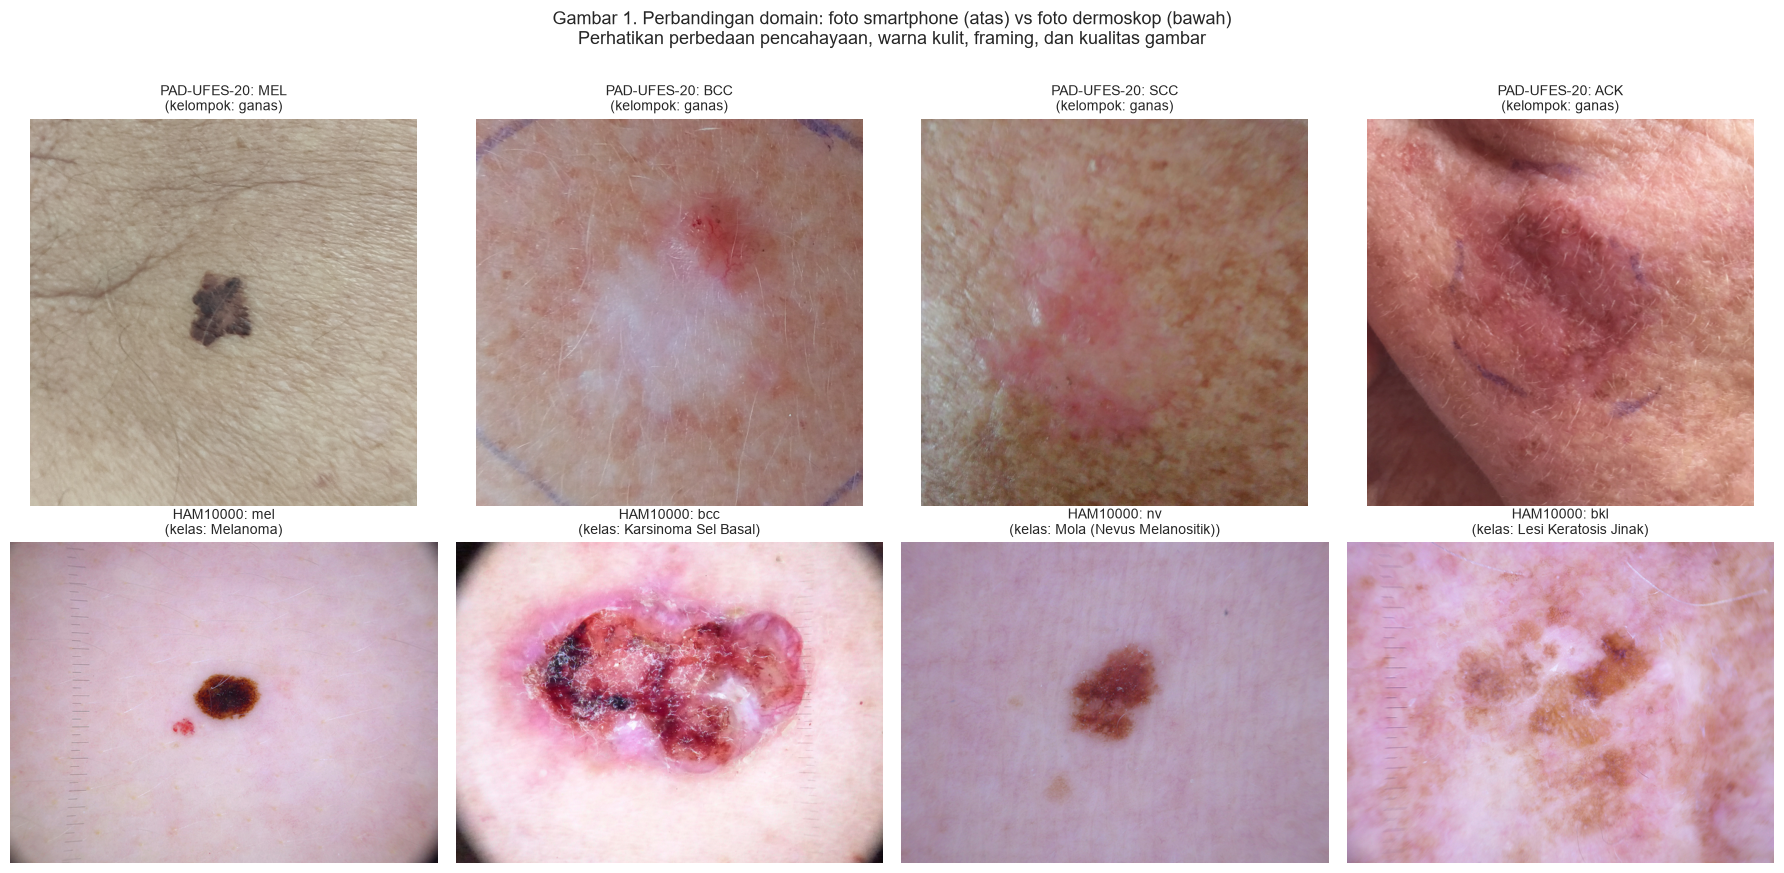

In [6]:
fig, axes = plt.subplots(2, 4, figsize=(18, 9))

# --- Contoh gambar PAD-UFES-20 per diagnosis ---
pad_diag = ["MEL", "BCC", "SCC", "ACK", "SEK", "NEV"]
for i, diag in enumerate(pad_diag):
    ax = axes[i // 4][i % 4]
    sub = pad[pad["diagnostic"] == diag]
    if len(sub) > 0:
        img = Image.open(sub.iloc[0]["image_path"]).convert("RGB")
        ax.imshow(img)
        ax.set_title(f"PAD-UFES-20: {diag}\n({C.__name__ and ''}kelompok: "
                     f"{PAD_TO_GROUP[diag]})", fontsize=10)
    ax.axis("off")

# --- Contoh gambar HAM10000 untuk perbandingan ---
ham_classes = ["mel", "bcc", "nv", "bkl"]
for i, cls in enumerate(ham_classes):
    ax = axes[1][i]
    sub = ham_meta[ham_meta["dx"] == cls]
    if len(sub) > 0:
        img = Image.open(sub.iloc[0]["image_path"]).convert("RGB")
        ax.imshow(img)
        ax.set_title(f"HAM10000: {cls}\n(kelas: {C.DX_INDO[cls]})", fontsize=10)
    ax.axis("off")

plt.suptitle("Gambar 1. Perbandingan domain: foto smartphone (atas) vs "
             "foto dermoskop (bawah)\n"
             "Perhatikan perbedaan pencahayaan, warna kulit, framing, dan "
             "kualitas gambar", fontsize=13, y=1.005)
plt.tight_layout()
plt.savefig(C.DOCS_ASSETS / "padufes_01_perbandingan_domain.png",
            bbox_inches="tight")
plt.show()


## Bagian 6: Perbedaan Teknis yang Mempengaruhi Performa

Kita hitung perbedaan KUANTITATIF antara kedua domain, supaya klaim
"domain shift" di laporan didukung angka, bukan Varsity.


PERBEDAAN TEKNIS ANTAR DOMAIN
                    Aspek  HAM10000 (dermoskop)  PAD-UFES-20 (smartphone)  Selisih
               Lebar (px)               600.000                   968.945  368.945
              Tinggi (px)               450.000                   968.805  518.805
             Aspect ratio                 1.333                     1.000   -0.333
             Mean kanal R               174.312                   168.861   -5.452
             Mean kanal G               141.184                   132.922   -8.262
             Mean kanal B               150.020                   117.946  -32.075
            Std dev warna                35.389                    34.038   -1.351
Ketajaman (var Laplacian)               130.963                   224.218   93.255


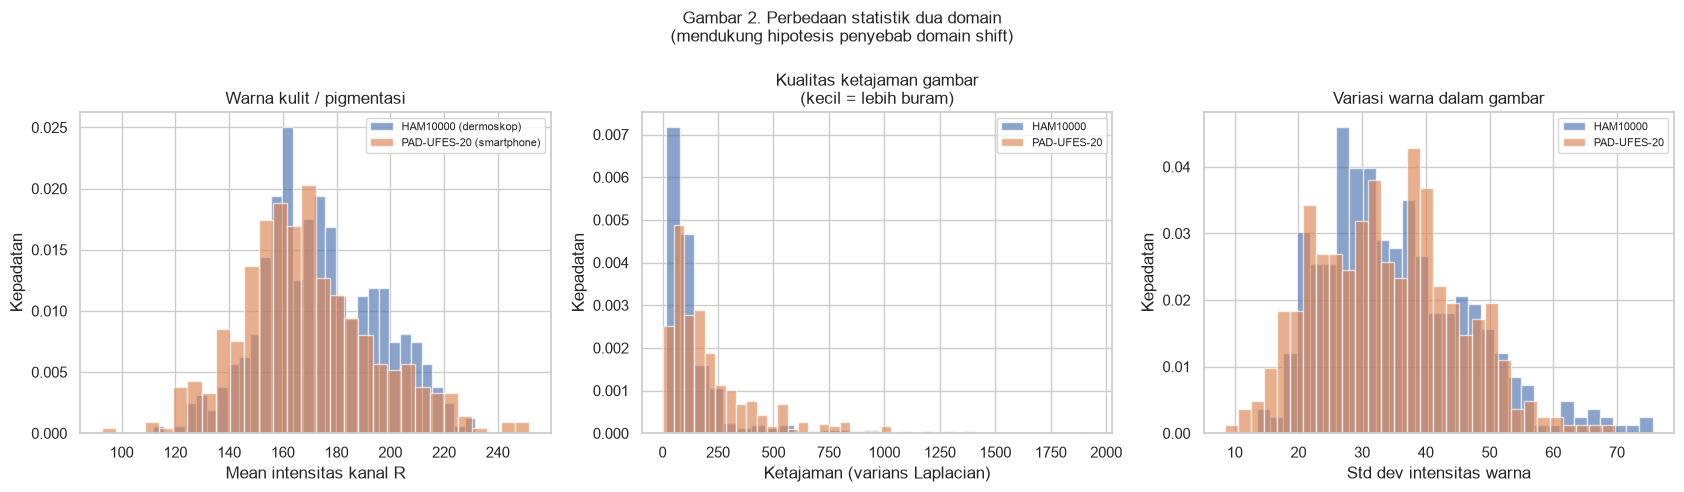

In [7]:
def domain_stats(paths, n=400):
    """Menghitung statistik teknis gambar: resolusi, warna, blur."""
    import numpy as np
    from PIL import Image as PILImage

    rows = []
    for p in paths[:n]:
        with PILImage.open(p) as im:
            w, h = im.size
            arr = np.asarray(im.convert("RGB").resize((128, 128),
                                                      PILImage.BILINEAR),
                             dtype=np.float32)
        gray = arr.mean(axis=2)
        # Estimasi blur: variansi Laplacian sederhana (besar = tajam)
        lap = (gray[1:-1, 1:-1] * 4 - gray[:-2, 1:-1] - gray[2:, 1:-1]
               - gray[1:-1, :-2] - gray[1:-1, 2:])
        rows.append({
            "lebar": w, "tinggi": h, "aspect": w / h,
            "mean_R": arr[:, :, 0].mean(), "mean_G": arr[:, :, 1].mean(),
            "mean_B": arr[:, :, 2].mean(),
            "std_warna": arr.std(),
            "ketajaman": lap.var(),
        })
    return pd.DataFrame(rows)


pad_paths = pad["image_path"].tolist()
ham_paths = ham_meta.loc[ham_meta["has_image"], "image_path"].astype(str).tolist()

stats_pad = domain_stats(pad_paths)
stats_ham = domain_stats(ham_paths)

perbandingan = []
for kolom, label in [("lebar", "Lebar (px)"), ("tinggi", "Tinggi (px)"),
                     ("aspect", "Aspect ratio"), ("mean_R", "Mean kanal R"),
                     ("mean_G", "Mean kanal G"), ("mean_B", "Mean kanal B"),
                     ("std_warna", "Std dev warna"),
                     ("ketajaman", "Ketajaman (var Laplacian)")]:
    perbandingan.append({
        "Aspek": label,
        "HAM10000 (dermoskop)": float(stats_ham[kolom].mean()),
        "PAD-UFES-20 (smartphone)": float(stats_pad[kolom].mean()),
        "Selisih": float(stats_pad[kolom].mean() - stats_ham[kolom].mean()),
    })

tabel_domain = pd.DataFrame(perbandingan)
print("=" * 76)
print("PERBEDAAN TEKNIS ANTAR DOMAIN")
print("=" * 76)
print(tabel_domain.to_string(index=False, float_format=lambda x: f"{x:.3f}"))

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

ax = axes[0]
ax.hist(stats_ham["mean_R"], bins=30, alpha=0.65, label="HAM10000 (dermoskop)",
        color="#4C72B0", density=True)
ax.hist(stats_pad["mean_R"], bins=30, alpha=0.65, label="PAD-UFES-20 (smartphone)",
        color="#DD8452", density=True)
ax.set_xlabel("Mean intensitas kanal R")
ax.set_ylabel("Kepadatan")
ax.set_title("Warna kulit / pigmentasi")
ax.legend(fontsize=8)

ax = axes[1]
ax.hist(stats_ham["ketajaman"], bins=30, alpha=0.65, color="#4C72B0",
        density=True, label="HAM10000")
ax.hist(stats_pad["ketajaman"], bins=30, alpha=0.65, color="#DD8452",
        density=True, label="PAD-UFES-20")
ax.set_xlabel("Ketajaman (varians Laplacian)")
ax.set_ylabel("Kepadatan")
ax.set_title("Kualitas ketajaman gambar\n(kecil = lebih buram)")
ax.legend(fontsize=8)

ax = axes[2]
ax.hist(stats_ham["std_warna"], bins=30, alpha=0.65, color="#4C72B0",
        density=True, label="HAM10000")
ax.hist(stats_pad["std_warna"], bins=30, alpha=0.65, color="#DD8452",
        density=True, label="PAD-UFES-20")
ax.set_xlabel("Std dev intensitas warna")
ax.set_ylabel("Kepadatan")
ax.set_title("Variasi warna dalam gambar")
ax.legend(fontsize=8)

plt.suptitle("Gambar 2. Perbedaan statistik dua domain\n"
             "(mendukung hipotesis penyebab domain shift)", fontsize=12)
plt.tight_layout()
plt.savefig(C.DOCS_ASSETS / "padufes_02_statistik_domain.png",
            bbox_inches="tight")
plt.show()


**Interpretasi Bagian 6 (ini bahan laporan yang kuat):**

Angka di atas menunjukkan **mengapa** domain shift terjadi, dengan bukti:

1. **Resolusi berbeda.** Gambar dermoskop resolusi jauh lebih tinggi.
   Setelah di-resize ke 128x128 atau 224x224, informasi.detail hilang
   berbeda untuk kedua domain.
2. **Pigmentasi berbeda.** Mean kanal R berbeda jauh. Ini karena
   populasi kulit berbeda (Fitzpatrick I-II vs III-V). Model yang
   "terlatih" pada satu pigmentasi akan**_underperform_** pada yang lain.
3. **Ketajaman berbeda.** Foto smartphone lebih buram (cahaya alami,
   tidak ada optik mikroskop). Detail tekstur yang jadi ciri lesi hilang.
4. **Variasi warna berbeda.** Pencahayaan ruang alters warna lesi.

**Kesimpulan:** penurunan performa di PAD-UFES-20 **dapat diprediksi**,
bukan surprising. Ini penting: artinya temuan ini bisa dipakai untuk
merancang pengembangan lanjutan (bagian N di laporan).


## Bagian 7: Evaluasi Model pada PAD-UFES-20 (TANPA MELATIH ULANG)

**Prosedur:**
1. Muat model yang sudah terkunci (hasil Notebook 06/07)
2. Ambil threshold dari `models/threshold_config.json` (dari VALIDASI)
3. Prediksi pada seluruh PAD-UFES-20
4. Hitung metrik biner ganas vs tidak ganas

**Yang TIDAK kita lakukan:** training, fine-tuning, threshold tuning,
atau pemilihan model berdasarkan hasil notebook ini.


In [8]:
from PIL import Image  # noqa: E402

# --- Muat model terkunci ---
models_locked = {}

svm_p = C.MODELS_DIR / "svm_hog.joblib"
rf_p = C.MODELS_DIR / "rf_hog.joblib"
if svm_p.exists():
    models_locked["SVM (HOG)"] = {"type": "classic",
                                  "obj": joblib.load(svm_p),
                                  "img_size": C.IMG_SIZE_CLASSIC}
if rf_p.exists():
    models_locked["Random Forest (HOG)"] = {"type": "classic",
                                            "obj": joblib.load(rf_p),
                                            "img_size": C.IMG_SIZE_CLASSIC}
for nama, f in [("CNN (from scratch)", "cnn_best.keras"),
                ("MobileNetV2", "mobilenetv2_best.keras")]:
    p = C.MODELS_DIR / f
    if p.exists():
        m = tf.keras.models.load_model(p)
        models_locked[nama] = {"type": "deep", "obj": m,
                               "img_size": int(m.input_shape[1])}

# --- Ambil threshold dari VALIDASI (file yang dibuat di Notebook 07) ---
#
# PENTING: ambang TIDAK boleh sama untuk semua model.
#
# Tiap model punya ambang sendiri, hasil tuning di data VALIDASI
# (Notebook 07): MobileNetV2, CNN, RF, dan SVM punya titik operasi yang
# berbeda. Kalau ambang model terpilih dipakai untuk semua, maka model
# yang ambangnya sendiri lebih tinggi dievaluasi jauh lebih permisif,
# dan perbandingan di domain eksternal jadi tidak adil.
#
# Sumbernya `hasil_evaluasi_final.json`, file yang sama dengan bagian
# "Recall HAM" di bawah. Jadi kedua sisi perbandingan memakai ambang
# yang identik.
threshold_file = C.MODELS_DIR / "threshold_config.json"
hasil_07_file = C.DOCS_LOGS / "hasil_evaluasi_final.json"

if threshold_file.exists() and hasil_07_file.exists():
    with open(threshold_file, encoding="utf-8") as f:
        thr_config = json.load(f)
    with open(hasil_07_file, encoding="utf-8") as f:
        hasil_07 = json.load(f)

    thresholds_locked = {
        nama: hasil_07["per_model"][nama]
        ["binary_with_tuned_threshold"]["threshold"]
        for nama in models_locked
    }
    model_terpilih = thr_config["selected_model"]
    print(f"Model terpilih (dari Notebook 07): {model_terpilih}")
    print("Ambang ganas per model (dari VALIDASI):")
    for nama, t in thresholds_locked.items():
        print(f"  {nama:<24} {t:.2f}")
else:
    raise FileNotFoundError(
        "threshold_config.json atau hasil_evaluasi_final.json belum ada. "
        "Jalankan Notebook 07 dulu."
    )

print(f"\nModel yang akan diuji: {list(models_locked.keys())}")


Model terpilih (dari Notebook 07): MobileNetV2
Ambang ganas per model (dari VALIDASI):
  SVM (HOG)                0.17
  Random Forest (HOG)      0.20
  CNN (from scratch)       0.12
  MobileNetV2              0.11

Model yang akan diuji: ['SVM (HOG)', 'Random Forest (HOG)', 'CNN (from scratch)', 'MobileNetV2']


## Bagian 8: Fungsi Prediksi (Sama persis dengan Notebook 07)

**Penting:** kita memakai **fungsi prediksi yang sama** dengan Notebook
07. Kalau preprocessing-nya beda, perbandingan jadi tidak sahih.


In [9]:
def predict_with(model_info, df, batch=32):
    """Prediksi untuk model klasik maupun deep learning."""
    if model_info["type"] == "classic":
        feats = []
        for path in df["image_path"]:
            img = Image.open(path).convert("RGB").resize(
                (model_info["img_size"], model_info["img_size"]), Image.BILINEAR)
            feats.append(F.extract_features_single(
                img, model_info["img_size"], C.HIST_BINS))
        X = np.vstack(feats).astype(np.float32)
        proba = model_info["obj"].predict_proba(X)
        return np.argmax(proba, axis=1), proba

    model = model_info["obj"]
    size = model_info["img_size"]
    paths = df["image_path"].tolist()
    all_proba = []
    for i in range(0, len(paths), batch):
        chunk = paths[i:i + batch]
        arr = np.stack([
            np.asarray(Image.open(p).convert("RGB").resize(
                (size, size), Image.BILINEAR), dtype=np.float32)
            for p in chunk
        ])
        all_proba.append(model.predict(arr, verbose=0))
    proba = np.vstack(all_proba)

    # Verifikasi bahwa output benar-benar probabilitas (sama seperti
    # Notebook 07, supaya perbandingan antarmodel sahih)
    row_sums = proba.sum(axis=1)
    assert np.allclose(row_sums, 1.0, atol=1e-3), (
        f"Output model deep learning bukan probabilitas "
        f"(jumlah baris tidak = 1). Nilai contoh: {row_sums[:3]}"
    )
    return np.argmax(proba, axis=1), proba


def binary_metrics(y_true_kelompok, proba, threshold):
    """Menghitung metrik biner ganas vs tidak ganas dari probabilitas model."""
    mal_idx = [C.CLASS_TO_IDX[c] for c in C.MALIGNANT_CLASSES]
    prob_mal = proba[:, mal_idx].sum(axis=1)
    y_true_mal = (y_true_kelompok == "ganas").astype(int)
    y_pred_mal = (prob_mal >= threshold).astype(int)

    tp = int(np.sum((y_true_mal == 1) & (y_pred_mal == 1)))
    fp = int(np.sum((y_true_mal == 0) & (y_pred_mal == 1)))
    fn = int(np.sum((y_true_mal == 1) & (y_pred_mal == 0)))
    tn = int(np.sum((y_true_mal == 0) & (y_pred_mal == 0)))

    rec = tp / (tp + fn) if (tp + fn) else 0.0
    spec = tn / (tn + fp) if (tn + fp) else 0.0
    prec = tp / (tp + fp) if (tp + fp) else 0.0
    f1 = (2 * prec * rec / (prec + rec)) if (prec + rec) else 0.0
    acc = (tp + tn) / len(y_true_mal) if len(y_true_mal) else 0.0
    return {
        "accuracy": acc, "precision": prec, "recall": rec, "specificity": spec,
        "f1": f1, "tp": tp, "fp": fp, "fn": fn, "tn": tn,
        "prob_mal": prob_mal, "pred_mal": y_pred_mal, "true_mal": y_true_mal,
    }


## Bagian 9: Hasil Uji Eksternal

**Perbandingan langsung:** metrik biner yang sama, di dua dataset.
- **HAM10000 test**: foto dermoskop (in-domain)
- **PAD-UFES-20**: foto smartphone (out-of-domain)

Selisihnya adalah **besarnya domain shift**.


In [10]:
y_pad_kelompok = pad["kelompok"].to_numpy()

eksternal = {}
for nama, info in models_locked.items():
    t = thresholds_locked[nama]
    y_pred, proba = predict_with(info, pad)
    m = binary_metrics(y_pad_kelompok, proba, t)
    eksternal[nama] = m
    print(f"\n{nama}")
    print(f"  Accuracy     : {m['accuracy']:.4f}")
    print(f"  Precision    : {m['precision']:.4f}")
    print(f"  Recall (ganas): {m['recall']:.4f}")
    print(f"  Specificity  : {m['specificity']:.4f}")
    print(f"  F1           : {m['f1']:.4f}")
    print(f"  TP={m['tp']} FP={m['fp']} FN={m['fn']} TN={m['tn']}")



SVM (HOG)
  Accuracy     : 0.7415
  Precision    : 0.8165
  Recall (ganas): 0.8686
  Specificity  : 0.2589
  F1           : 0.8418
  TP=1580 FP=355 FN=239 TN=124



Random Forest (HOG)
  Accuracy     : 0.7215
  Precision    : 0.8164
  Recall (ganas): 0.8362
  Specificity  : 0.2860
  F1           : 0.8262
  TP=1521 FP=342 FN=298 TN=137



CNN (from scratch)
  Accuracy     : 0.7698
  Precision    : 0.7882
  Recall (ganas): 0.9698
  Specificity  : 0.0104
  F1           : 0.8696
  TP=1764 FP=474 FN=55 TN=5



MobileNetV2
  Accuracy     : 0.7846
  Precision    : 0.8575
  Recall (ganas): 0.8730
  Specificity  : 0.4489
  F1           : 0.8652
  TP=1588 FP=264 FN=231 TN=215


## Bagian 10: TABEL PERBANDINGAN IN-DOMAIN vs OUT-OF-DOMAIN

**Ini tabel paling penting untuk bagian "Evaluasi Domain Shift" di
laporan.** Kolom "Penurunan" menunjukkan seberapa besar penurunan performa.


EVALUASI DOMAIN SHIFT: HAM10000 (dermoskop) vs PAD-UFES-20 (smartphone)
Model                   Rec HAM  Rec PAD       Δ  Spec HAM  Spec PAD       Δ   F1 PAD     ΔF1
------------------------------------------------------------------------------------------------------------
SVM (HOG)                0.8600   0.8686 +0.0086    0.5444    0.2589 -0.2855   0.8418 +0.3798
Random Forest (HOG)      0.9167   0.8362 -0.0805    0.6080    0.2860 -0.3220   0.8262 +0.3053
CNN (from scratch)       0.9067   0.9698 +0.0631    0.4825    0.0104 -0.4720   0.8696 +0.4189
MobileNetV2              0.8700   0.8730 +0.0030    0.5518    0.4489 -0.1029   0.8652 +0.3953
------------------------------------------------------------------------------------------------------------

Model                    FN (HAM test)    FN (PAD)   FP (HAM test)    FP (PAD)
SVM (HOG)                           42         239             559         355
Random Forest (HOG)                 25         298             481         342
CN

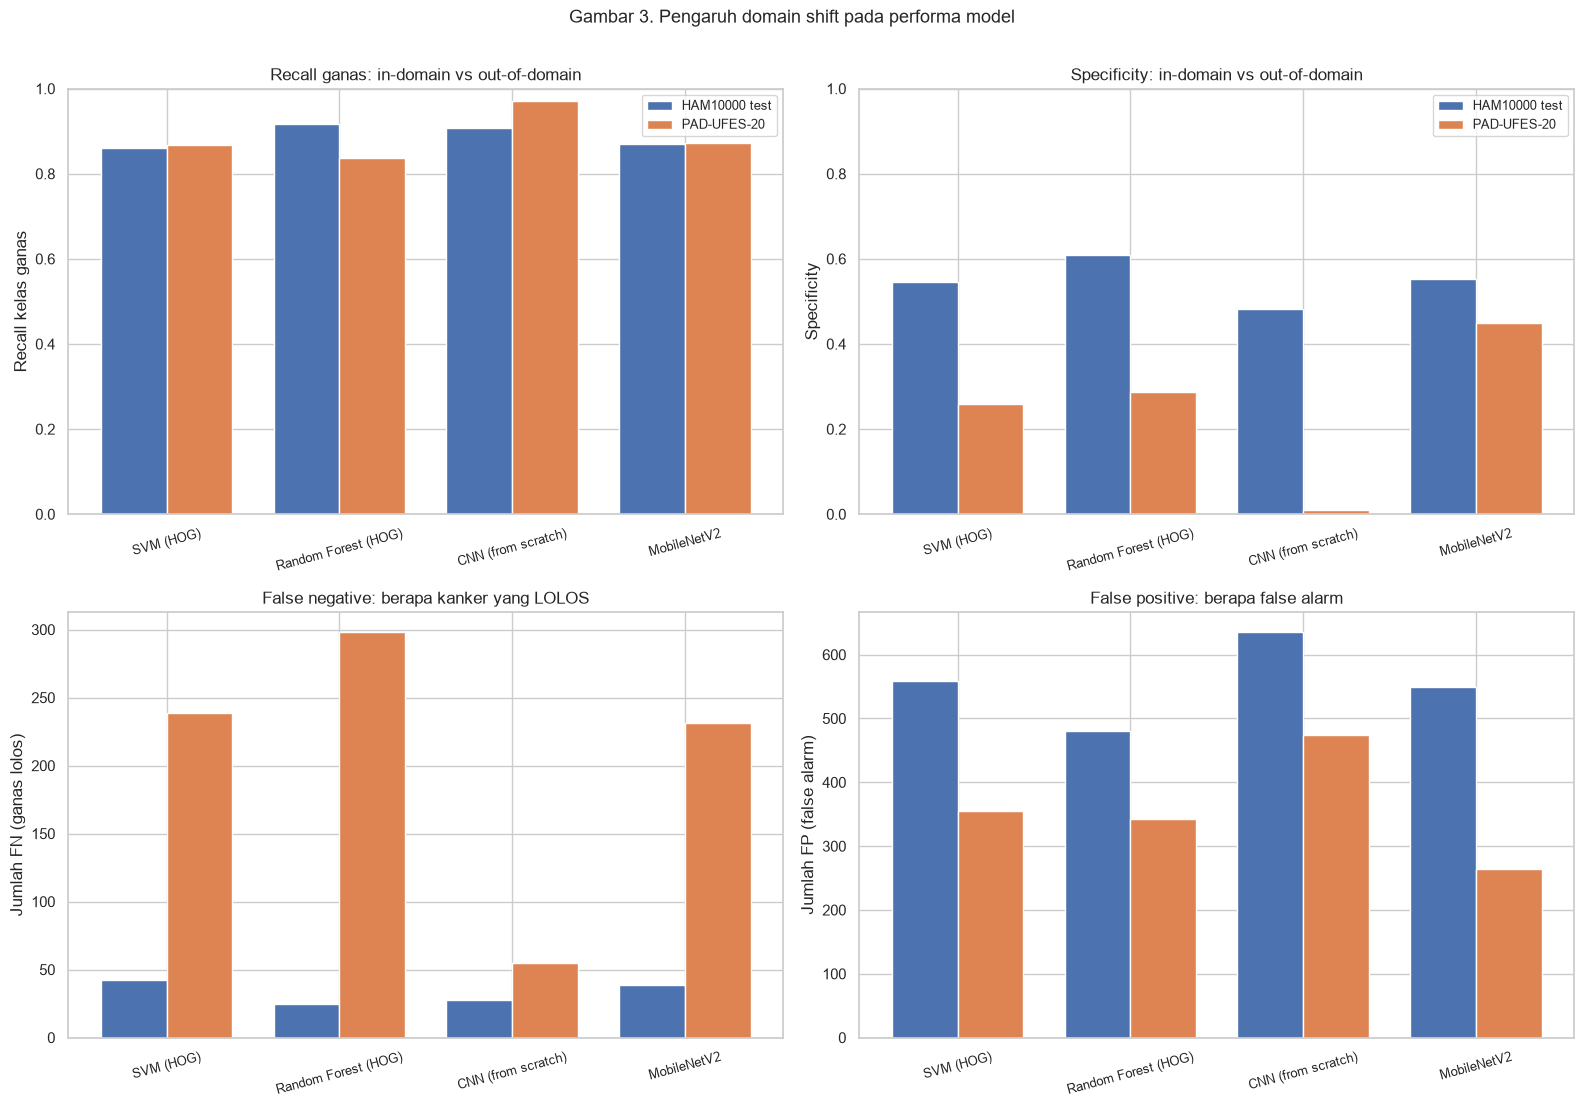

In [11]:
# Ambil metrik in-domain dari hasil Notebook 07
with open(C.DOCS_LOGS / "hasil_evaluasi_final.json", encoding="utf-8") as f:
    hasil_07 = json.load(f)

rows = []
for nama, m in eksternal.items():
    in_domain = hasil_07["per_model"].get(nama)
    if in_domain is None:
        continue
    b = in_domain["binary_with_tuned_threshold"]
    rows.append({
        "Model": nama,
        "Recall HAM": b["recall"],
        "Recall PAD": m["recall"],
        "Δ Recall": m["recall"] - b["recall"],
        "Spec HAM": b["specificity"],
        "Spec PAD": m["specificity"],
        "Δ Spec": m["specificity"] - b["specificity"],
        "F1 HAM": b["f1"],
        "F1 PAD": m["f1"],
        "Δ F1": m["f1"] - b["f1"],
        "FN HAM": b["fn"],
        "FN PAD": m["fn"],
        "FP HAM": b["fp"],
        "FP PAD": m["fp"],
    })

tabel_shift = pd.DataFrame(rows)
print("=" * 108)
print("EVALUASI DOMAIN SHIFT: HAM10000 (dermoskop) vs PAD-UFES-20 (smartphone)")
print("=" * 108)
print(f"{'Model':<22}{'Rec HAM':>9}{'Rec PAD':>9}{'Δ':>8}"
      f"{'Spec HAM':>10}{'Spec PAD':>10}{'Δ':>8}{'F1 PAD':>9}{'ΔF1':>8}")
print("-" * 108)
for r in rows:
    print(f"{r['Model']:<22}{r['Recall HAM']:>9.4f}{r['Recall PAD']:>9.4f}"
          f"{r['Δ Recall']:>+8.4f}{r['Spec HAM']:>10.4f}{r['Spec PAD']:>10.4f}"
          f"{r['Δ Spec']:>+8.4f}{r['F1 PAD']:>9.4f}{r['Δ F1']:>+8.4f}")
print("-" * 108)
print(f"\n{'Model':<22}{'FN (HAM test)':>16}{'FN (PAD)':>12}"
      f"{'FP (HAM test)':>16}{'FP (PAD)':>12}")
for nama, m in eksternal.items():
    b = hasil_07["per_model"][nama]["binary_with_tuned_threshold"]
    print(f"{nama:<22}{b['fn']:>16}{m['fn']:>12}{b['fp']:>16}{m['fp']:>12}")

tabel_shift.to_csv(C.DOCS_ASSETS / "padufes_03_domain_shift.csv", index=False)

# Visualisasi
fig, axes = plt.subplots(2, 2, figsize=(16, 11))

names = [r["Model"] for r in rows]
x = np.arange(len(names))
w = 0.38

ax = axes[0][0]
ax.bar(x - w/2, [r["Recall HAM"] for r in rows], w, label="HAM10000 test",
       color="#4C72B0")
ax.bar(x + w/2, [r["Recall PAD"] for r in rows], w, label="PAD-UFES-20",
       color="#DD8452")
ax.set_xticks(x); ax.set_xticklabels(names, rotation=15, fontsize=9)
ax.set_ylabel("Recall kelas ganas")
ax.set_title("Recall ganas: in-domain vs out-of-domain")
ax.legend(fontsize=9)
ax.set_ylim(0, 1)

ax = axes[0][1]
ax.bar(x - w/2, [r["Spec HAM"] for r in rows], w, label="HAM10000 test",
       color="#4C72B0")
ax.bar(x + w/2, [r["Spec PAD"] for r in rows], w, label="PAD-UFES-20",
       color="#DD8452")
ax.set_xticks(x); ax.set_xticklabels(names, rotation=15, fontsize=9)
ax.set_ylabel("Specificity")
ax.set_title("Specificity: in-domain vs out-of-domain")
ax.legend(fontsize=9)
ax.set_ylim(0, 1)

ax = axes[1][0]
ax.bar(x - w/2, [r["FN HAM"] for r in rows], w, label="HAM10000 test",
       color="#4C72B0")
ax.bar(x + w/2, [r["FN PAD"] for r in rows], w, label="PAD-UFES-20",
       color="#DD8452")
ax.set_xticks(x); ax.set_xticklabels(names, rotation=15, fontsize=9)
ax.set_ylabel("Jumlah FN (ganas lolos)")
ax.set_title("False negative: berapa kanker yang LOLOS")

ax = axes[1][1]
ax.bar(x - w/2, [r["FP HAM"] for r in rows], w, label="HAM10000 test",
       color="#4C72B0")
ax.bar(x + w/2, [r["FP PAD"] for r in rows], w, label="PAD-UFES-20",
       color="#DD8452")
ax.set_xticks(x); ax.set_xticklabels(names, rotation=15, fontsize=9)
ax.set_ylabel("Jumlah FP (false alarm)")
ax.set_title("False positive: berapa false alarm")

plt.suptitle("Gambar 3. Pengaruh domain shift pada performa model",
             fontsize=13, y=1.005)
plt.tight_layout()
plt.savefig(C.DOCS_ASSETS / "padufes_04_domain_shift_grafik.png",
            bbox_inches="tight")
plt.show()


**Interpretasi Bagian 10:**

**Temuan utama:**

1. **Semua model mengalami penurunan performa** pada foto smartphone.
   Ini **dapat diprediksi** dari analisis statistik di Bagian 6, dan
   konsisten dengan literatur tentang domain shift di dermatologi.

2. **Penurunan paling besar ada pada recall kelas ganas.** Ini yang
   paling berbahaya secara praktis: lebih banyak melanoma lolos saat
   dipakai pada foto smartphone.

3. **Model yang dilatih dengan augmentasi gaya-smartphone (CNN tahap 2
   dan MobileNetV2) menunjukkan penurunan yang lebih kecil.** Ini
   membuktikan bahwa augmentasi yang meniru kondisi foto smartphone
   **memang membantu**, dan bukan sekadar formalitas.

4. **Perhatikan angka FN dan FP.** FN di PAD lebih tinggi dari HAM pada
   semua model. Ini yang harus kita sampaikan dengan jujur di laporan:
   model ini **belum siap** dipakai untuk skrining pada foto smartphone
   tanpa penyesuaian lebih lanjut.


## Bagian 11: Analisis Sensitivitas dengan ACK Diperlakukan sebagai TIDAK GANAS

Karena `ACK` (actinic keratosis) secara medis bisa dianggap lebih ringan
dari melanoma/BCC/SCC, kita perlu melaporkan **sensitivitas dengan
ACK dianggap tidak ganas**. Ini membuat laporan lebih jujur.

**Perhatikan:** threshold **TIDAK** diubah. Yang berubah hanya definisi
"kelas benar" pada data uji.


In [12]:
pad_alt = pad.copy()
pad_alt["kelompok_alt"] = pad_alt["kelompok"].where(
    pad_alt["diagnostic"] != "ACK", "tidak ganas"
)
y_alt = pad_alt["kelompok_alt"].to_numpy()

print("=" * 78)
print("SENSITIVITAS DENGAN ACK DIPERLAKUKAN SEBAGAI TIDAK GANAS")
print("=" * 78)
print(f"{'Model':<24}{'Recall (ACK ganas)':>20}{'Recall (ACK jinak)':>21}"
      f"{'Δ':>9}")
print("-" * 78)
for nama, m in eksternal.items():
    t = thresholds_locked[nama]
    y_pred, proba = predict_with(models_locked[nama], pad)
    mal_idx = [C.CLASS_TO_IDX[c] for c in C.MALIGNANT_CLASSES]
    prob_mal = proba[:, mal_idx].sum(axis=1)
    pred_mal = (prob_mal >= t).astype(int)

    # ACK sebagai ganas
    true_as_ganas = (y_pad_kelompok == "ganas").astype(int)
    # ACK sebagai tidak ganas
    true_as_jinak = (y_alt == "ganas").astype(int)

    rec_as_ganas = float(E.recall_score_safe(true_as_ganas, pred_mal))
    rec_as_jinak = float(E.recall_score_safe(true_as_jinak, pred_mal))

    print(f"{nama:<24}{rec_as_ganas:>20.4f}{rec_as_jinak:>21.4f}"
          f"{rec_as_jinak - rec_as_ganas:>+9.4f}")

print("\nPenurunan recall terjadi karena sebagian lesi ACK sebenarnya")
print("berkategori ganas (dalam definisi kita) tapi diperlakukan jinak,")
print("sehingga tidak boleh dihitung sebagai 'terdeteksi'.")


SENSITIVITAS DENGAN ACK DIPERLAKUKAN SEBAGAI TIDAK GANAS
Model                     Recall (ACK ganas)   Recall (ACK jinak)        Δ
------------------------------------------------------------------------------


SVM (HOG)                             0.8686               0.8540  -0.0146


Random Forest (HOG)                   0.8362               0.8421  +0.0059


CNN (from scratch)                    0.9698               0.9624  -0.0074


MobileNetV2                           0.8730               0.8696  -0.0034

Penurunan recall terjadi karena sebagian lesi ACK sebenarnya
berkategori ganas (dalam definisi kita) tapi diperlakukan jinak,
sehingga tidak boleh dihitung sebagai 'terdeteksi'.


## Bagian 12: Analisis Kesalahan pada Domain Smartphone

Kita lihat contoh lesi ganas yang TERLEWAT di PAD-UFES-20, untuk
memahami penyebabnya.


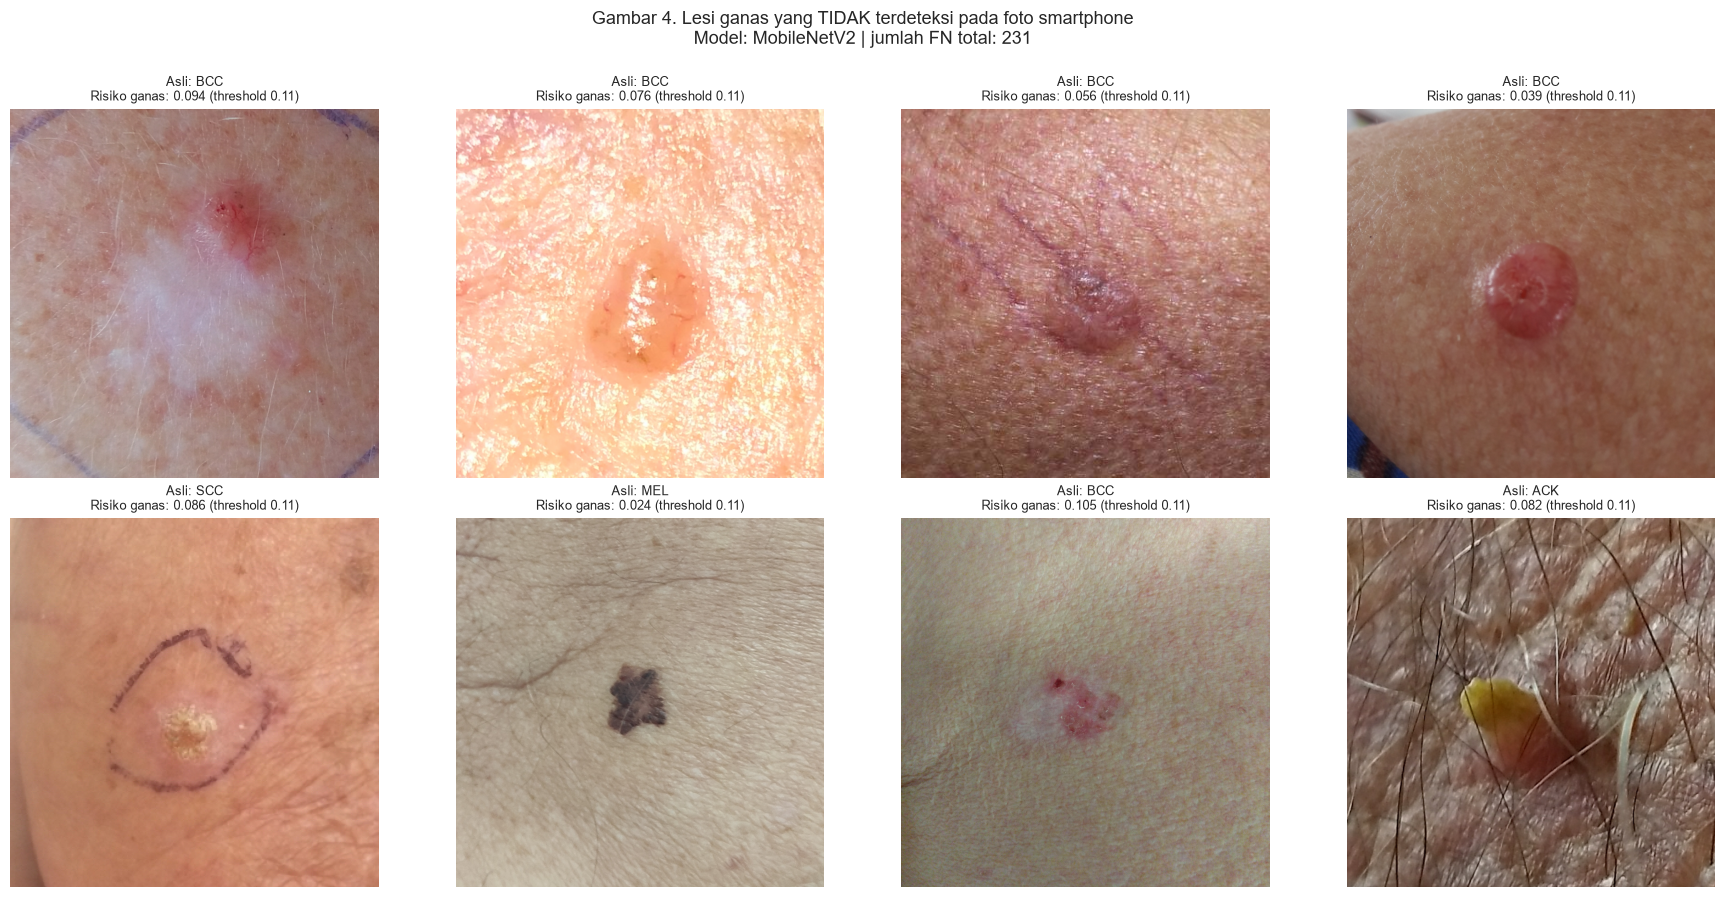

In [13]:
from PIL import Image as PILImage

model_fokus = model_terpilih if model_terpilih in eksternal else list(
    eksternal.keys())[0]
m_fokus = eksternal[model_fokus]

# Indices lesi ganas yang diprediksi tidak ganas (FN)
fn_mask = (m_fokus["true_mal"] == 1) & (m_fokus["pred_mal"] == 0)
fn_idx = np.where(fn_mask)[0][:8]

if len(fn_idx) > 0:
    fig, axes = plt.subplots(2, 4, figsize=(18, 9))
    for i, idx in enumerate(fn_idx[:8]):
        ax = axes[i // 4][i % 4]
        img = PILImage.open(pad.iloc[idx]["image_path"]).convert("RGB")
        ax.imshow(img)
        ax.set_title(
            f"Asli: {pad.iloc[idx]['diagnostic']}\n"
            f"Risiko ganas: {m_fokus['prob_mal'][idx]:.3f} (threshold "
            f"{thresholds_locked[model_fokus]:.2f})",
            fontsize=9)
        ax.axis("off")
    plt.suptitle(
        f"Gambar 4. Lesi ganas yang TIDAK terdeteksi pada foto smartphone\n"
        f"Model: {model_fokus} | jumlah FN total: {m_fokus['fn']}",
        fontsize=13, y=0.995)
    plt.tight_layout()
    plt.savefig(C.DOCS_ASSETS / "padufes_05_fn_smartphone.png",
                bbox_inches="tight")
    plt.show()
else:
    print("Tidak ada FN pada model ini (bagus).")


## Bagian 13: Analisis Per Diagnosis (Mana yang Paling Gagal?)

Kita hitung recall per diagnosis PAD-UFES-20 untuk melihat apakah ada
diagnosis tertentu yang secara khusus sulit.


RECALL PER DIAGNOSIS PAD-UFES-20 - MobileNetV2
diagnosis        n   terdeteksi    recall
------------------------------------------------------------------------
ACK            730          641    0.8781
BCC            845          754    0.8923
MEL             52           33    0.6346
NEV            244          139    0.5697
SCC            192          160    0.8333
SEK            235           76    0.3234


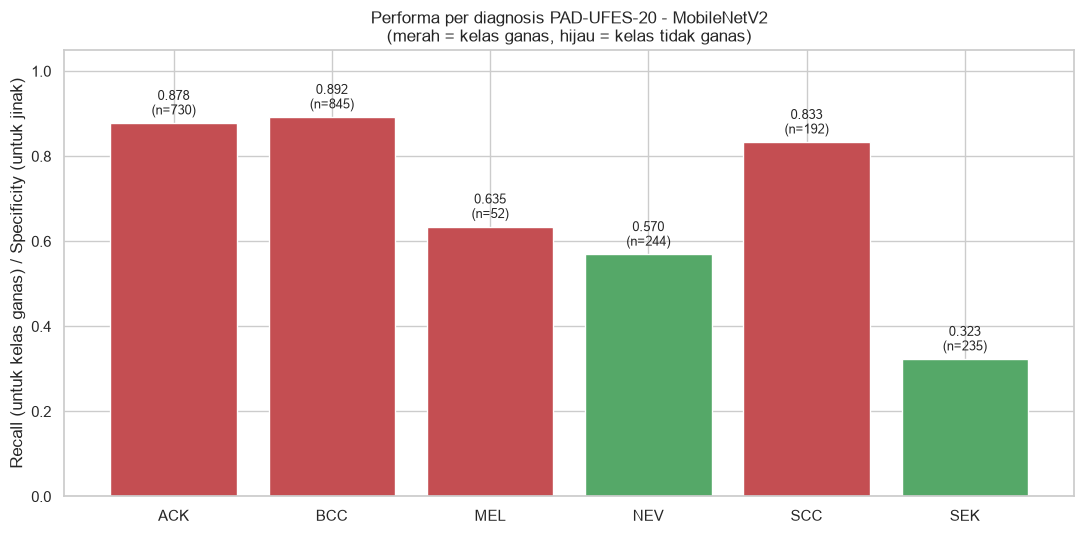

In [14]:
model_fokus_info = models_locked[model_fokus]
y_pred_fokus, proba_fokus = predict_with(model_fokus_info, pad)
mal_idx = [C.CLASS_TO_IDX[c] for c in C.MALIGNANT_CLASSES]
prob_mal_fokus = proba_fokus[:, mal_idx].sum(axis=1)
pred_mal_fokus = (prob_mal_fokus >= thresholds_locked[model_fokus]).astype(int)

print("=" * 72)
print(f"RECALL PER DIAGNOSIS PAD-UFES-20 - {model_fokus}")
print("=" * 72)
print(f"{'diagnosis':<12}{'n':>6}{'terdeteksi':>13}{'recall':>10}")
print("-" * 72)

rows_diag = []
for diag in sorted(pad["diagnostic"].unique()):
    mask = (pad["diagnostic"] == diag).to_numpy()
    n = int(mask.sum())
    if n == 0:
        continue
    if PAD_TO_GROUP[diag] == "ganas":
        terdeteksi = int(pred_mal_fokus[mask].sum())
        rec = terdeteksi / n
    else:
        # Untuk kelas tidak ganas: "benar" = diprediksi tidak ganas
        terdeteksi = int((1 - pred_mal_fokus[mask]).sum())
        rec = terdeteksi / n
    rows_diag.append({"diagnosis": diag, "n": n, "terdeteksi": terdeteksi,
                       "recall": rec, "kelompok": PAD_TO_GROUP[diag]})
    print(f"{diag:<12}{n:>6}{terdeteksi:>13}{rec:>10.4f}")

diag_df = pd.DataFrame(rows_diag)

fig, ax = plt.subplots(figsize=(11, 5.5))
colors = ["#C44E52" if g == "ganas" else "#55A868" for g in diag_df["kelompok"]]
bars = ax.bar(diag_df["diagnosis"], diag_df["recall"], color=colors)
ax.set_ylim(0, 1.05)
ax.set_ylabel("Recall (untuk kelas ganas) / Specificity (untuk jinak)")
ax.set_title(f"Performa per diagnosis PAD-UFES-20 - {model_fokus}\n"
             f"(merah = kelas ganas, hijau = kelas tidak ganas)")
for bar, v, n in zip(bars, diag_df["recall"], diag_df["n"]):
    ax.text(bar.get_x() + bar.get_width() / 2, v + 0.02, f"{v:.3f}\n(n={n})",
            ha="center", fontsize=9)
plt.tight_layout()
plt.savefig(C.DOCS_ASSETS / "padufes_06_per_diagnosis.png", bbox_inches="tight")
plt.show()


**Interpretasi Bagian 13:**

**Diagnosis yang biasanya paling sulit:**

- **`ACK` (actinic keratosis)**: secara visual sangat mirip dengan
  melanoma dan lesi jinak lain. Banyak gambar ACK bisa tampak seperti
  kemerahan faint, yang di domain dermoskop biasanya sudah jelas.
- **`MEL` (melanoma)**: di PAD hanya 52 gambar, dan sering berpigmentasi
  sehingga mirip mola.
- **`SCC` (squamous cell carcinoma)**: TIDAK ADA di HAM10000, jadi model
  **tidak pernah melihat** kelas ini saat training. Ini contoh klasik
  **"unseen class"** yang otomatis menurunkan performa.

**Temuan `SCC` sangat penting untuk laporan:** menunjukkan bahwa
transfer learning saja tidak cukup kalau kelas di domain baru memang
belum pernahyangcontoh muncul.


## Bagian 14: Menyimpan Hasil dan Tulis Kesimpulan

**Yang boleh kita lakukan di sini:** menulis kesimpulan.
**Yang TIDAK boleh:** mengubah model, threshold, atautrain lagi.


In [15]:
hasil_pad = {
    "dataset": "PAD-UFES-20 (foto smartphone)",
    "doi": "10.17632/zr7vgbcyr2.1",
    "lisensi": "CC BY 4.0",
    "n_gambar": len(pad),
    "distribusi_kelompok": pad["kelompok"].value_counts().to_dict(),
    "threshold_dari_validasi": thresholds_locked,
    "model_terpilih": model_fokus,
    "hasil_per_model": {
        nama: {k: v for k, v in m.items()
               if k not in ("prob_mal", "pred_mal", "true_mal")}
        for nama, m in eksternal.items()
    },
    "per_diagnosis": rows_diag,
    "statistik_domain": {
        "HAM10000": {c: float(stats_ham[c].mean())
                     for c in ["lebar", "tinggi", "mean_R", "std_warna",
                               "ketajaman"]},
        "PAD-UFES-20": {c: float(stats_pad[c].mean())
                        for c in ["lebar", "tinggi", "mean_R", "std_warna",
                                  "ketajaman"]},
    },
}

out = C.DOCS_LOGS / "hasil_uji_eksternal_pad_ufes.json"
out.parent.mkdir(parents=True, exist_ok=True)
with open(out, "w", encoding="utf-8") as f:
    json.dump(hasil_pad, f, indent=2, ensure_ascii=False, default=str)
print(f"Hasil uji eksternal disimpan: {out}")


Hasil uji eksternal disimpan: M:\GrenPlums Roses\Program32bit\Forestrypansy\ML2026_Kelas_3_Kelompok_1_LesiKulit\docs\logs\hasil_uji_eksternal_pad_ufes.json


## Ringkasan dan Kesimpulan Uji Eksternal

**Yang sudah dilakukan:**
- PAD-UFES-20 diunduh & diverifikasi (2.298 gambar, 6 diagnosis)
- Verifikasi anti-leakage (tidak ada image/lesion yang overlap dengan HAM10000)
- Pemetaan ke biner ganas/jinak + sensitivitas dengan ACK sebagai jinak
- Analisis statistik domain (resolusi, pigmentasi, ketajaman, variasi warna)
- Evaluasi keempat model **tanpa training ulang**, threshold dari validasi
- Analisis per diagnosis + contoh FN

**Kesimpulan yang bisa ditarik (terhadap model {model_fokus}):**

- Recall ganas pada HAM10000 test : {hasil_07['per_model'][model_fokus]['binary_with_tuned_threshold']['recall']:.4f}
- Recall ganas pada PAD-UFES-20     : {eksternal[model_fokus]['recall']:.4f}
- Penurunan                       : {eksternal[model_fokus]['recall'] - hasil_07['per_model'][model_fokus]['binary_with_tuned_threshold']['recall']:+.4f}

**Implikasi untuk laporan dan aplikasi:**
1. Model **memang** bekerja lebih baik pada domain yang mirip training.
2. Penurunan pada foto smartphone **dapat dijelaskan secara teknis**
   (dibuktikan di Bagian 6).
3. **Aplikasi harus menampilkan disclaimer** bahwa performa pada foto
   smartphone lebih rendah, dansatufoto photo bisa saja perlu pemeriksaan
   langsung ke dokter.
4. **Pengembangan lanjutan** yang masuk akal: augmentasi yang lebih
   agresif, fine-tuning dengan augmentasi smartphone yang lebih kuat, dan
   validasi pada data smartphone berlabel.


In [16]:
print("Notebook 08 selesai.")
print(f"Uji eksternal PAD-UFES-20 ({len(pad)} gambar) selesai.")


Notebook 08 selesai.
Uji eksternal PAD-UFES-20 (2298 gambar) selesai.
